# Simulated Annealing — User Input + Iteration Path

Minimize the objective function **f(x) = x² + 10 sin(x)**. Enter **x0, T0, alpha and T_min** when prompted. The graph shows the actual state after every iteration, connected in sequence with iteration numbers and arrows.

In [22]:
# USER INPUT
x0 = float(input('Enter x0: '))
T0 = float(input('Enter T0: '))
alpha = float(input('Enter alpha: '))
T_min = float(input('Enter T_min: '))

print('\nParameters entered:')
print(f'x0 = {x0}, T0 = {T0}, alpha = {alpha}, T_min = {T_min}')


Parameters entered:
x0 = 2.5, T0 = 50.0, alpha = 0.6, T_min = 0.001


In [23]:
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fixed settings — everything other than the requested parameters remains fixed
neighbour_step = 1
iterations_per_temperature = 1
seed = 42

# Objective function from the question/image:
# f(x) = x^2 + 10 sin(x)
def f(x):
    return x**2 + 10*np.sin(x)

random.seed(seed)
np.random.seed(seed)

# Simulated Annealing
current_x = x0
current_value = f(current_x)
temperature = T0
history = []
iteration = 0

# Store initial state as iteration 0
history.append({
    'Iteration': 0,
    'Temperature': temperature,
    'Current x': current_x,
    'Current f(x)': current_value,
    'Candidate x': np.nan,
    'Candidate f(x)': np.nan,
    'Delta': np.nan,
    'Acceptance Probability': np.nan,
    'Accepted': True
})

while temperature >= T_min:
    for _ in range(iterations_per_temperature):
        iteration += 1
        candidate_x = current_x + random.choice([-neighbour_step, neighbour_step])
        candidate_value = f(candidate_x)
        delta = candidate_value - current_value

        if delta <= 0:
            accepted = True
            probability = 1.0
        else:
            probability = math.exp(-delta / temperature)
            accepted = random.random() < probability

        # Record the state AFTER the acceptance decision.
        if accepted:
            current_x = candidate_x
            current_value = candidate_value

        history.append({
            'Iteration': iteration,
            'Temperature': temperature,
            'Current x': current_x,
            'Current f(x)': current_value,
            'Candidate x': candidate_x,
            'Candidate f(x)': candidate_value,
            'Delta': delta,
            'Acceptance Probability': probability,
            'Accepted': accepted
        })

    temperature *= alpha

results = pd.DataFrame(history)
print(f'Total iterations: {iteration}')
print(f'Final x: {current_x}')
print(f'Final f(x): {current_value}')
results

Total iterations: 22
Final x: -1.5
Final f(x): -7.724949866040545


,Iteration,Temperature,Current x,Current f(x),Candidate x,Candidate f(x),Delta,Acceptance Probability,Accepted
0,0,50.000000,2.5,12.234721,NaN,NaN,NaN,NaN,True
1,1,50.000000,1.5,12.224950,1.5,12.224950,-0.009772,1.000000e+00,True
2,2,30.000000,0.5,5.044255,0.5,5.044255,-7.180694,1.000000e+00,True
3,3,18.000000,1.5,12.224950,1.5,12.224950,7.180694,6.710394e-01,True
4,4,10.800000,0.5,5.044255,0.5,5.044255,-7.180694,1.000000e+00,True
5,5,6.480000,-0.5,-4.544255,-0.5,-4.544255,-9.588511,1.000000e+00,True
6,6,3.888000,-1.5,-7.724950,-1.5,-7.724950,-3.180694,1.000000e+00,True
7,7,2.332800,-0.5,-4.544255,-0.5,-4.544255,3.180694,2.557726e-01,True
8,8,1.399680,-1.5,-7.724950,-1.5,-7.724950,-3.180694,1.000000e+00,True
9,9,0.839808,-1.5,-7.724950,-2.5,0.265279,7.990228,7.378527e-05,False


In [24]:
# Final result
print('Simulated Annealing Result')
print('--------------------------')
print('Objective function: f(x) = x² + 10 sin(x)')
print(f'Best x found = {current_x}')
print(f'Minimum f(x) = {current_value}')

Simulated Annealing Result
--------------------------
Objective function: f(x) = x² + 10 sin(x)
Best x found = -1.5
Minimum f(x) = -7.724949866040545


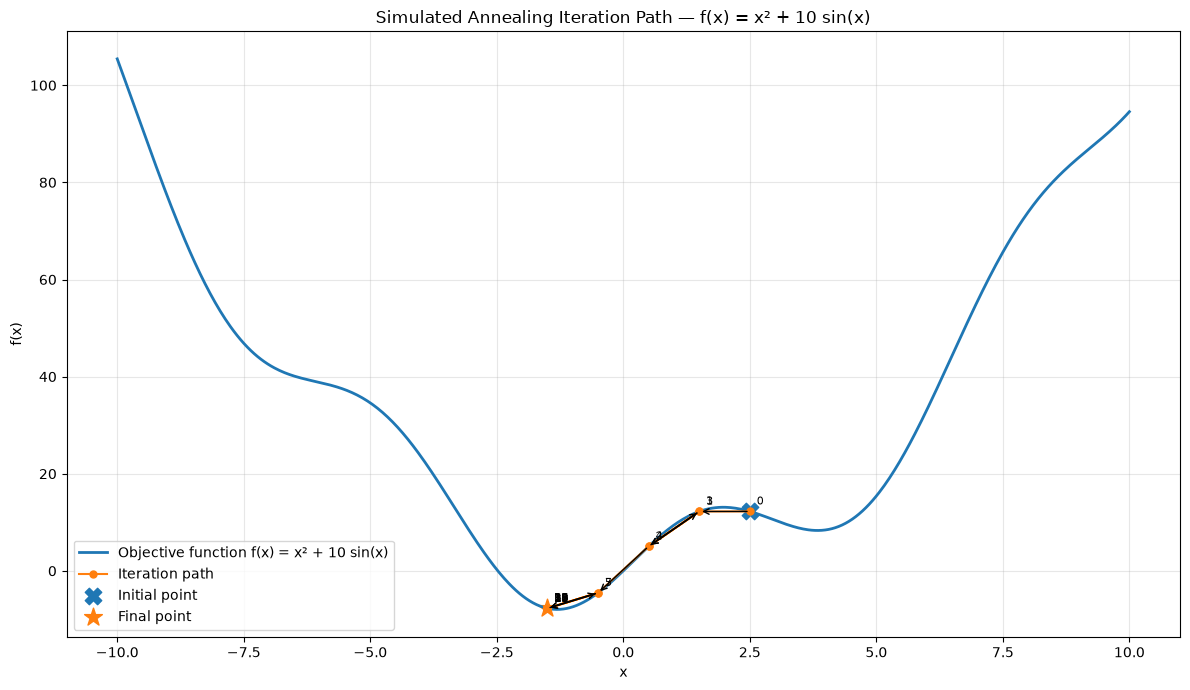

In [25]:
# GRAPH — ACTUAL ITERATION PATH
# Every plotted point is the state AFTER that iteration.

path_x = results['Current x'].to_numpy()
path_y = results['Current f(x)'].to_numpy()

# Show a useful fixed domain for f(x) = x² + 10 sin(x)
xmin = min(path_x.min() - 2, -10)
xmax = max(path_x.max() + 2, 10)

x_values = np.linspace(xmin, xmax, 600)
y_values = f(x_values)

plt.figure(figsize=(12, 7))
plt.plot(x_values, y_values, linewidth=2, label='Objective function f(x) = x² + 10 sin(x)')

# Connect the actual iteration states in chronological order
plt.plot(path_x, path_y, marker='o', markersize=5, linewidth=1.5, label='Iteration path')

# Direction arrows: iteration i -> iteration i+1
for i in range(len(results)-1):
    x1, y1 = path_x[i], path_y[i]
    x2, y2 = path_x[i+1], path_y[i+1]
    if x1 != x2 or y1 != y2:
        plt.annotate('', xy=(x2, y2), xytext=(x1, y1),
                     arrowprops=dict(arrowstyle='->', linewidth=1))

# Initial and final points
plt.scatter(x0, f(x0), s=140, marker='X', label='Initial point')
plt.scatter(current_x, current_value, s=180, marker='*', label='Final point')

# Iteration labels
for i, row in results.iterrows():
    plt.annotate(str(int(row['Iteration'])),
                 (row['Current x'], row['Current f(x)']),
                 xytext=(5,5), textcoords='offset points', fontsize=8)

plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Simulated Annealing Iteration Path — f(x) = x² + 10 sin(x)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()